# Lab 1

## Task 1

### b)

max |Im| = 0.7246111675533227


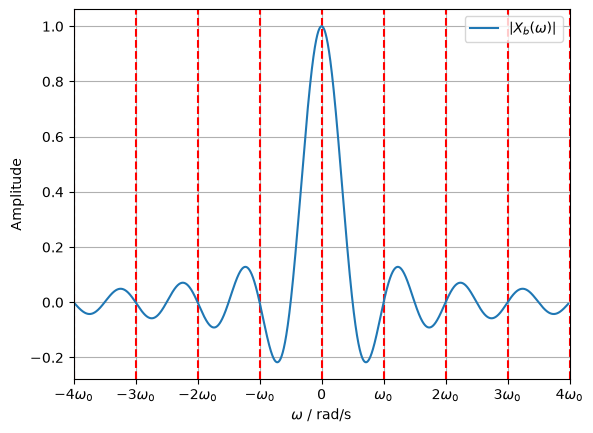

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b_0 = 1
T_b = 1

min_x = -25
max_x = 25

w = np.arange(min_x, max_x, 0.01)

X_b = b_0 * T_b * np.sinc((w * T_b) / (2 * np.pi)) * np.exp((-1j * w * T_b) / 2)

fig, ax = plt.subplots()
ax.grid()

# fig.subplots_adjust(hspace=(2 * np.pi) / T_b)

ax.set_xlim(min_x, max_x)

ax.set_xlabel('$\\omega$ / rad/s')
ax.set_ylabel('Amplitude')

w0 = 2 * np.pi / T_b
ks = range(-4, 5) 

for k in ks:
    plt.axvline(x=k * w0, color='r', linestyle='--')   # no label, so not in the legend

def lbl(k):
    if k == 0:  return '$0$'
    if k == 1:  return r'$\omega_0$'
    if k == -1: return r'$-\omega_0$'
    return rf'${k}\omega_0$'

plt.xticks([k * w0 for k in ks], [lbl(k) for k in ks])

print(f"max |Im| = {np.max(np.abs(np.imag(X_b)))}")
ax.plot(w, np.real(X_b), label="$\\left|X_b(\\omega)\\right|$")
ax.legend()

### c)

The choice of $T_b$ affects the size of the range of frequencies the signal occupies in the spectrum. A smaller $T_b$ makes the range of frequencies larger, while a larger $T_b$ makes it smaller. The trade-off is having a larger bitrate $R$ requires a larger range of frequencies.

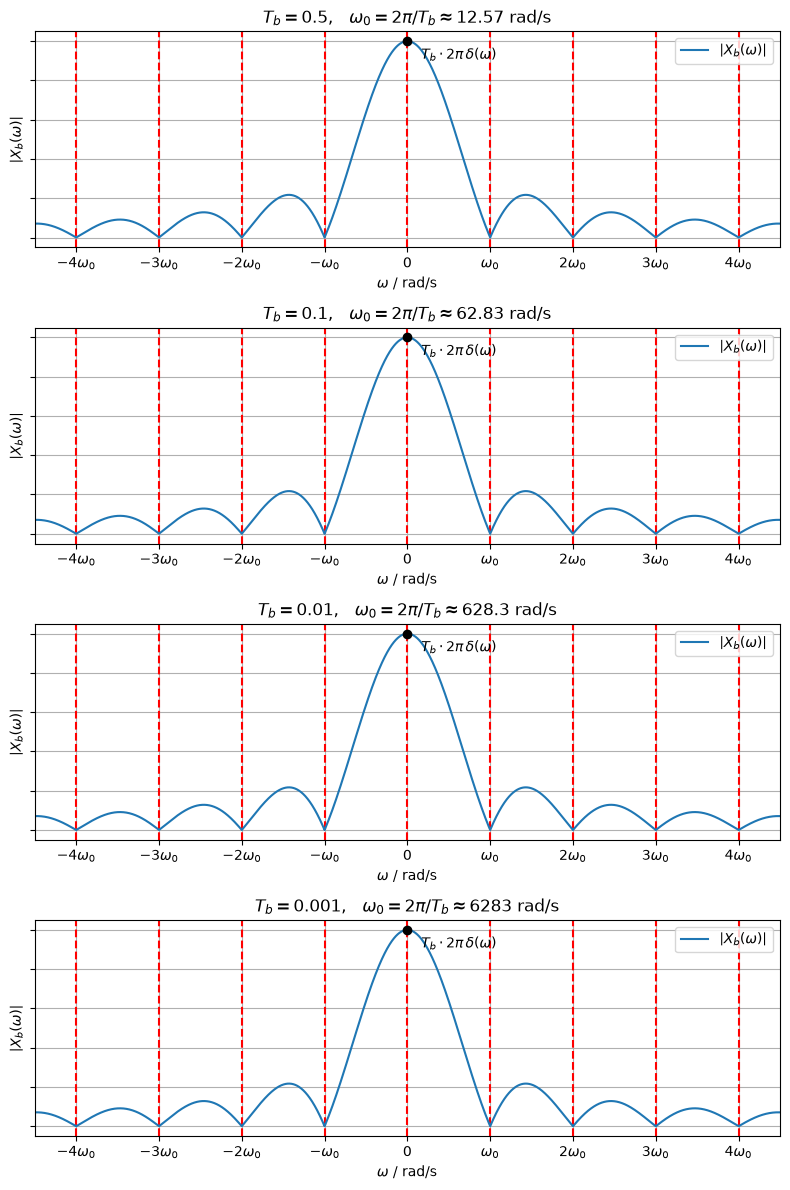

In [7]:
def lbl(k):
    if k == 0:  return '$0$'
    if k == 1:  return r'$\omega_0$'
    if k == -1: return r'$-\omega_0$'
    return rf'${k}\omega_0$'

def plot_X_b(T_b, ax, n_lobes=4):
    # The x-range scales with T_b: show n_lobes zero crossings on each side
    w0 = 2 * np.pi / T_b
    max_x = (n_lobes + 0.5) * w0

    w = np.linspace(-max_x, max_x, 5000)
    X_b = T_b * np.sinc((w * T_b) / (2 * np.pi)) * np.exp((-1j * w * T_b) / 2)

    ax.grid()
    ax.set_xlim(-max_x, max_x)
    ax.set_xlabel('$\\omega$ / rad/s')
    ax.set_ylabel('$\\left|X_b(\\omega)\\right|$')
    ax.tick_params(axis='y', labelleft=False)   # hide the y tick values
    ax.set_title(f'$T_b = {T_b}$,   $\\omega_0 = 2\\pi / T_b \\approx {w0:.4g}$ rad/s')

    # Zero crossings at k * w0
    ks = range(-n_lobes, n_lobes + 1)
    for k in ks:
        ax.axvline(x=k * w0, color='r', linestyle='--')   # not in the legend
    ax.set_xticks([k * w0 for k in ks], [lbl(k) for k in ks])

    ax.plot(w, np.abs(X_b), label="$\\left|X_b(\\omega)\\right|$")

    # Mark the highest point
    i_max = np.argmax(np.abs(X_b))
    w_max, y_max = w[i_max], np.abs(X_b)[i_max]
    ax.plot(w_max, y_max, 'ko')
    ax.annotate(r'$T_b \cdot 2\pi\,\delta(\omega)$', xy=(w_max, y_max),
                xytext=(10, -5), textcoords='offset points', va='top')

    ax.legend()

T_b_values = [0.5, 0.1, 0.01, 0.001]

fig, axs = plt.subplots(len(T_b_values), 1, figsize=(8, 3 * len(T_b_values)))
for T_b, ax in zip(T_b_values, axs):
    plot_X_b(T_b, ax)

fig.tight_layout()
plt.show()

## Task 2

### b)

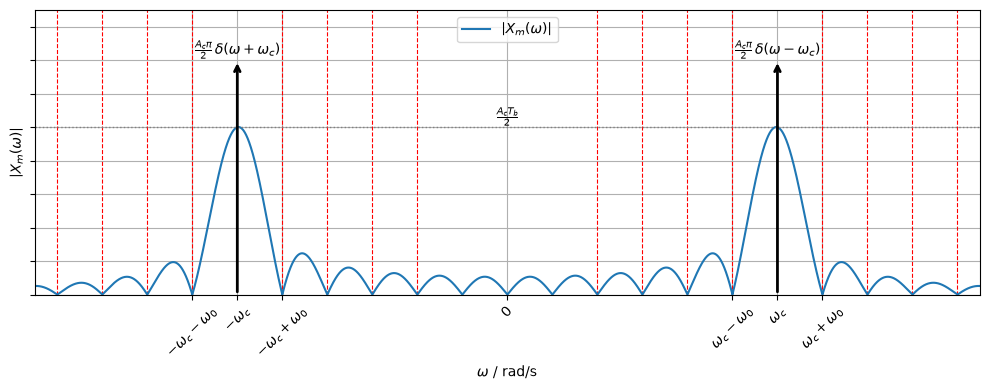

In [8]:
b_0 = 1
T_b = 1
A_c = 1

w0 = 2 * np.pi / T_b
w_c = 6 * w0           # carrier well above the lobe width, so the copies don't overlap

min_x = -(w_c + 4.5 * w0)
max_x = w_c + 4.5 * w0

# Sinc part of X_b(ω); the π·δ(ω) from the 0.5 offset is drawn as arrows below
X_b_func = lambda w: b_0 * T_b * np.sinc((w * T_b) / (2 * np.pi)) * np.exp((-1j * w * T_b) / 2)

w = np.arange(min_x, max_x, 0.01)

X_b_w_plus_w_c = X_b_func(w + w_c)
X_b_w_minus_w_c = X_b_func(w - w_c)

X_m = (A_c * 1j) / 2 * (X_b_w_plus_w_c - X_b_w_minus_w_c)

fig, ax = plt.subplots(figsize=(10, 4))
ax.grid()
ax.set_xlim(min_x, max_x)
ax.set_xlabel('$\\omega$ / rad/s')
ax.set_ylabel('$\\left|X_m(\\omega)\\right|$')
ax.tick_params(axis='y', labelleft=False)   # hide the y tick values

# Zero crossings at ±ω_c + k·ω0 (not in the legend)
for c in (-w_c, w_c):
    for k in range(-4, 5):
        if k != 0:
            ax.axvline(c + k * w0, color='r', linestyle='--', lw=0.8)

ax.set_xticks([-w_c - w0, -w_c, -w_c + w0, 0, w_c - w0, w_c, w_c + w0],
              [r'$-\omega_c-\omega_0$', r'$-\omega_c$', r'$-\omega_c+\omega_0$', '$0$',
               r'$\omega_c-\omega_0$', r'$\omega_c$', r'$\omega_c+\omega_0$'],
              rotation=45)

ax.plot(w, np.abs(X_m), label="$\\left|X_m(\\omega)\\right|$")

# Impulses from the 0.5 offset: weight A_c·π/2 at ±ω_c (the arrow height is only for show)
arrow_h = 1.4 * A_c * T_b / 2
for c, txt in ((-w_c, r'$\frac{A_c\pi}{2}\,\delta(\omega + \omega_c)$'),
               ( w_c, r'$\frac{A_c\pi}{2}\,\delta(\omega - \omega_c)$')):
    ax.annotate('', xy=(c, arrow_h), xytext=(c, 0),
                arrowprops=dict(arrowstyle='->', lw=2, color='k'))
    ax.text(c, arrow_h, txt, ha='center', va='bottom')

# Peak value of the sinc lobes: A_c·T_b/2
ax.axhline(A_c * T_b / 2, color='gray', linestyle=':', lw=1)
ax.text(0, A_c * T_b / 2, r'$\frac{A_c T_b}{2}$', ha='center', va='bottom')

ax.set_ylim(0, 1.7 * A_c * T_b / 2)
ax.legend(loc='upper center')
fig.tight_layout()

### c) & d)

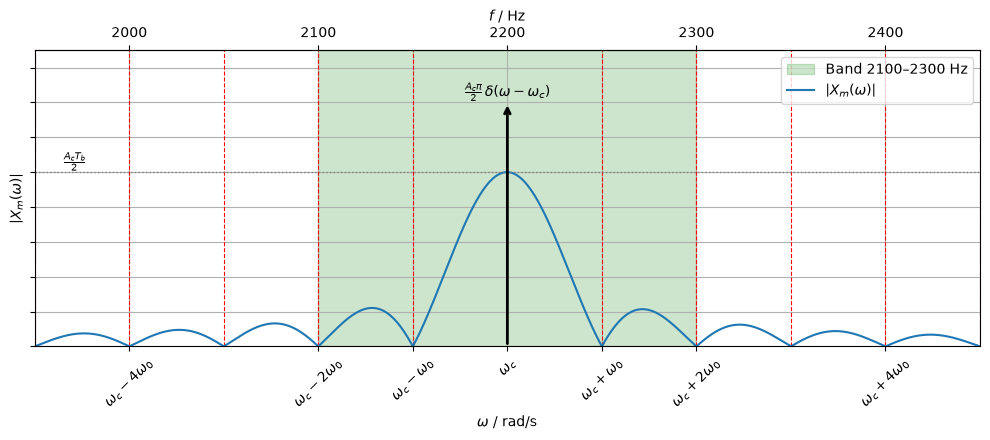

In [16]:
b_0 = 1
T_b = 1 / 50
A_c = 1

w0 = 2 * np.pi / T_b
w_c = 13_823

# Our frequency band: 2100 Hz – 2300 Hz, in rad/s
f_low, f_high = 2100, 2300
w_low, w_high = 2 * np.pi * f_low, 2 * np.pi * f_high

# Zoom in on the positive copy around ω_c (the negative side is its mirror image)
min_x = w_low - 3 * w0
max_x = w_high + 3 * w0

# Sinc part of X_b(ω); the π·δ(ω) from the 0.5 offset is drawn as an arrow below
X_b_func = lambda w: b_0 * T_b * np.sinc((w * T_b) / (2 * np.pi)) * np.exp((-1j * w * T_b) / 2)

w = np.linspace(min_x, max_x, 20000)

X_b_w_plus_w_c = X_b_func(w + w_c)
X_b_w_minus_w_c = X_b_func(w - w_c)

X_m = (A_c * 1j) / 2 * (X_b_w_plus_w_c - X_b_w_minus_w_c)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.grid()
ax.set_xlim(min_x, max_x)
ax.set_xlabel('$\\omega$ / rad/s')
ax.set_ylabel('$\\left|X_m(\\omega)\\right|$')
ax.tick_params(axis='y', labelleft=False)   # hide the y tick values

# Frequency in Hz along the top, so the band edges can be read off directly
top = ax.secondary_xaxis('top', functions=(lambda w: w / (2 * np.pi), lambda f: 2 * np.pi * f))
top.set_xlabel('$f$ / Hz')

# Frequency band
ax.axvspan(w_low, w_high, color='green', alpha=0.2, label=f'Band {f_low}–{f_high} Hz')

# Zero crossings at ω_c + k·ω0 (not in the legend)
k_max = int((max_x - w_c) // w0)
for k in range(-k_max, k_max + 1):
    if k != 0:
        ax.axvline(w_c + k * w0, color='r', linestyle='--', lw=0.8)

def lbl_c(k):
    if k == 0:  return r'$\omega_c$'
    if k == 1:  return r'$\omega_c+\omega_0$'
    if k == -1: return r'$\omega_c-\omega_0$'
    return rf'$\omega_c{k:+d}\omega_0$'

ticks = [k for k in range(-k_max, k_max + 1) if k % 2 == 0 or abs(k) == 1]
ax.set_xticks([w_c + k * w0 for k in ticks], [lbl_c(k) for k in ticks], rotation=45)

ax.plot(w, np.abs(X_m), label="$\\left|X_m(\\omega)\\right|$")

# Impulse from the 0.5 offset: weight A_c·π/2 at ω_c (the arrow height is only for show)
arrow_h = 1.4 * A_c * T_b / 2
ax.annotate('', xy=(w_c, arrow_h), xytext=(w_c, 0),
            arrowprops=dict(arrowstyle='->', lw=2, color='k'))
ax.text(w_c, arrow_h, r'$\frac{A_c\pi}{2}\,\delta(\omega - \omega_c)$', ha='center', va='bottom')

# Peak value of the sinc lobe: A_c·T_b/2
ax.axhline(A_c * T_b / 2, color='gray', linestyle=':', lw=1)
ax.text(min_x + 0.3 * w0, A_c * T_b / 2, r'$\frac{A_c T_b}{2}$', va='bottom')

ax.set_ylim(0, 1.7 * A_c * T_b / 2)
ax.legend(loc='upper right')
fig.tight_layout()

## Task 3

### a)

max |Im| = 0.7246111675533227


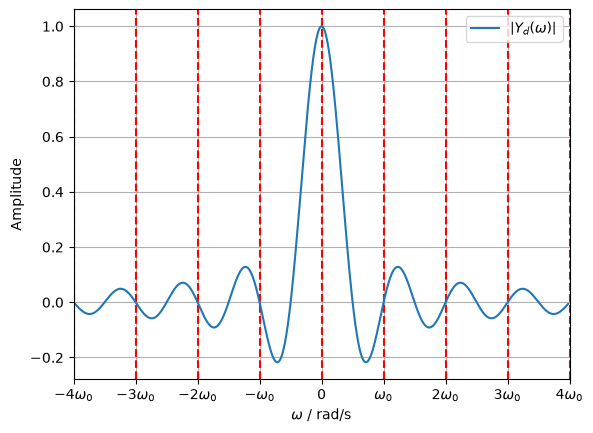

In [27]:
Y_d = A_c * X_b

fig, ax = plt.subplots()
ax.grid()

ax.set_xlim(min_x, max_x)

ax.set_xlabel('$\\omega$ / rad/s')
ax.set_ylabel('Amplitude')

w0 = 2 * np.pi / T_b
ks = range(-4, 5) 

for k in ks:
    plt.axvline(x=k * w0, color='r', linestyle='--')   # no label, so not in the legend

def lbl(k):
    if k == 0:  return '$0$'
    if k == 1:  return r'$\omega_0$'
    if k == -1: return r'$-\omega_0$'
    return rf'${k}\omega_0$'

plt.xticks([k * w0 for k in ks], [lbl(k) for k in ks])

print(f"max |Im| = {np.max(np.abs(np.imag(Y_d)))}")
ax.plot(w, np.real(Y_d), label="$\\left|Y_d(\\omega)\\right|$")
ax.legend()

### b)

Yes, if you also send the information of $A_c$'s value.

## Task 4

### a)